# Zadanie 2A — BloodMNIST

**Cel:** przygotuj dane obrazowe, wytrenuj i oceń model klasyfikujący osiem typów komórek krwi, a następnie zastosuj samodzielnie wybraną metodę wyjaśniania predykcji.

In [1]:
# Importy i ustawienia
import copy
import hashlib
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from huggingface_hub import hf_hub_download
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Ziarno losowości: te same wagi startowe, ta sama kolejność danych, te same wyniki.
RS = 42
random.seed(RS)
np.random.seed(RS)
torch.manual_seed(RS)

# GPU, jeśli jest dostępne, w przeciwnym razie procesor.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("urządzenie:", DEVICE)
pd.set_option("display.width", 200)

urządzenie: cpu


In [2]:
DATA_DIR = Path("data/zadanie-2a")
DATA_DIR.mkdir(parents=True, exist_ok=True)

data_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-2A",
    filename="original/bloodmnist.npz",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
data = np.load(data_path)
print(data.files)

['train_images', 'train_labels', 'val_images', 'val_labels', 'test_images', 'test_labels']


## A — Poznanie i przygotowanie danych

Sprawdź strukturę obrazów, kanały, klasy, liczebności i jakość danych. Zachowaj oficjalne podziały treningowy, walidacyjny i testowy. Wykonaj preprocessing i augmentację; wszystkie decyzje zależne od danych podejmuj wyłącznie na zbiorze treningowym.

In [3]:
# A1. Struktura obrazów i kanały
# Plik .npz to kilka tablic NumPy zapisanych razem. Wyciągamy je po nazwach.
X_train, y_train = data["train_images"], data["train_labels"].ravel()   # ravel: (N, 1) zamienia na (N,)
X_val, y_val = data["val_images"], data["val_labels"].ravel()
X_test, y_test = data["test_images"], data["test_labels"].ravel()

for nazwa, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{nazwa:5s} obrazy {X.shape}, typ {X.dtype}, wartości {X.min()} do {X.max()}, etykiety {y.shape}")
# Kształt (N, 28, 28, 3): N obrazów, 28 x 28 pikseli, 3 kanały kolorów (R, G, B), liczby 0 do 255.

# Nazwy klas według opisu zbioru MedMNIST (BloodMNIST).
KLASY = ["bazofil", "eozynofil", "erytroblast", "niedojrz. granulocyt",
         "limfocyt", "monocyt", "neutrofil", "płytka krwi"]

train obrazy (11959, 28, 28, 3), typ uint8, wartości 0 do 255, etykiety (11959,)
val   obrazy (1712, 28, 28, 3), typ uint8, wartości 0 do 255, etykiety (1712,)
test  obrazy (3421, 28, 28, 3), typ uint8, wartości 0 do 255, etykiety (3421,)


                      train  val  test
bazofil                 852  122   244
eozynofil              2181  312   624
erytroblast            1085  155   311
niedojrz. granulocyt   2026  290   579
limfocyt                849  122   243
monocyt                 993  143   284
neutrofil              2330  333   666
płytka krwi            1643  235   470

udział klas (train):
bazofil                 0.071
eozynofil               0.182
erytroblast             0.091
niedojrz. granulocyt    0.169
limfocyt                0.071
monocyt                 0.083
neutrofil               0.195
płytka krwi             0.137
Name: train, dtype: float64


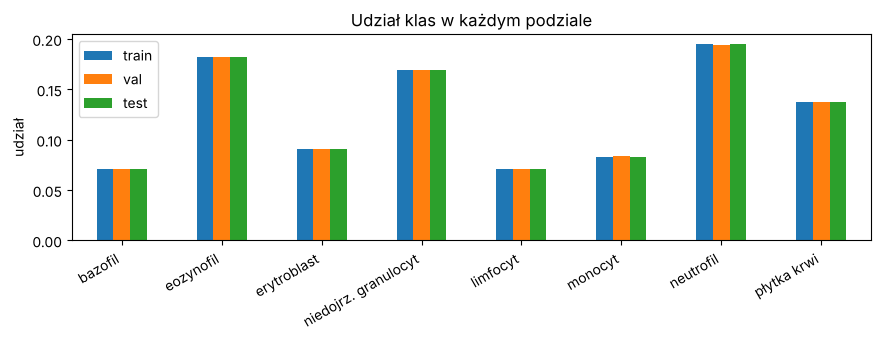

In [4]:
# A2. Liczebność klas w każdym podziale
liczebnosc = pd.DataFrame({
    "train": np.bincount(y_train, minlength=8),
    "val": np.bincount(y_val, minlength=8),
    "test": np.bincount(y_test, minlength=8),
}, index=KLASY)
print(liczebnosc)
print("\nudział klas (train):")
print((liczebnosc["train"] / liczebnosc["train"].sum()).round(3))

plt.figure(figsize=(9, 3.5))
(liczebnosc / liczebnosc.sum()).plot(kind="bar", ax=plt.gca())
plt.title("Udział klas w każdym podziale")
plt.ylabel("udział")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

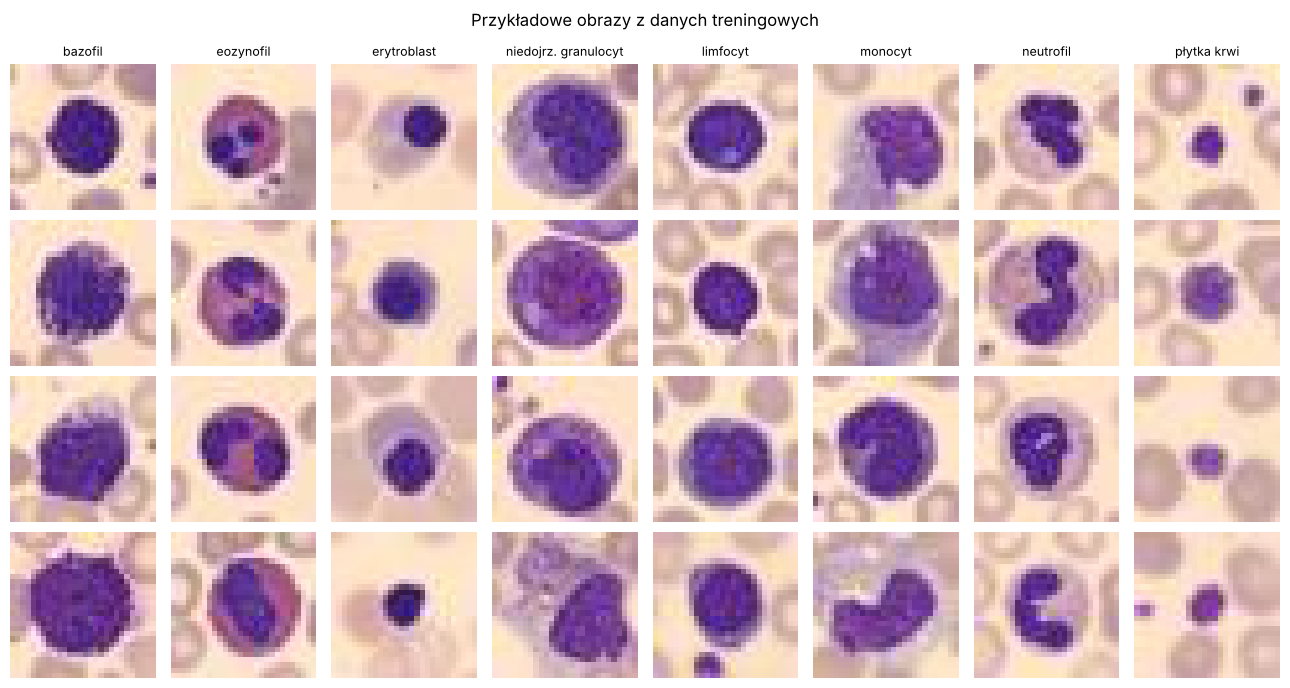

In [5]:
# A3. Przykładowe obrazy każdej klasy
fig, axes = plt.subplots(4, 8, figsize=(13, 7))
for klasa in range(8):
    indeksy = np.where(y_train == klasa)[0][:4]          # 4 pierwsze obrazy danej klasy
    for wiersz, i in enumerate(indeksy):
        axes[wiersz, klasa].imshow(X_train[i])
        axes[wiersz, klasa].axis("off")
    axes[0, klasa].set_title(KLASY[klasa], fontsize=9)
plt.suptitle("Przykładowe obrazy z danych treningowych")
plt.tight_layout()
plt.show()

In [6]:
# A4. Jakość danych: puste obrazy i duplikaty
# Obraz bez żadnej zmienności (wszystkie piksele takie same) byłby uszkodzony.
puste = sum(int(obraz.std() == 0) for obraz in X_train)
print("obrazy bez zmienności w train:", puste)


# Duplikaty szukamy przez "odcisk palca" obrazu (hash MD5 z jego bajtów):
# identyczne obrazy mają identyczny hash.
def hashe(obrazy):
    return [hashlib.md5(obraz.tobytes()).hexdigest() for obraz in obrazy]


h_train, h_val, h_test = set(hashe(X_train)), set(hashe(X_val)), set(hashe(X_test))
print("duplikaty wewnątrz train:", len(X_train) - len(h_train))
print("te same obrazy w train i val:", len(h_train & h_val))
print("te same obrazy w train i test:", len(h_train & h_test))
print("te same obrazy w val i test:", len(h_val & h_test))

obrazy bez zmienności w train: 0
duplikaty wewnątrz train: 8
te same obrazy w train i val: 3
te same obrazy w train i test: 5
te same obrazy w val i test: 1


In [7]:
# A5. Normalizacja: średnia i odchylenie liczone TYLKO na zbiorze treningowym
# Każdy kanał osobno, po przeskalowaniu pikseli do zakresu 0 do 1.
SREDNIA = (X_train / 255.0).mean(axis=(0, 1, 2))      # średnia po obrazach, wierszach i kolumnach
ODCHYLENIE = (X_train / 255.0).std(axis=(0, 1, 2))
print("średnia kanałów R, G, B:", SREDNIA.round(3))
print("odchylenie kanałów R, G, B:", ODCHYLENIE.round(3))

średnia kanałów R, G, B: [0.794 0.66  0.696]
odchylenie kanałów R, G, B: [0.216 0.242 0.118]


In [8]:
# A6. Preprocessing i augmentacja
# ToTensor: obraz (28, 28, 3) z liczbami 0 do 255 zamienia na tensor (3, 28, 28) z liczbami 0 do 1.
# Normalize: od każdego kanału odejmuje średnią i dzieli przez odchylenie (z train).
# Augmentacja (tylko dla train): losowe odbicia w poziomie i w pionie. Komórka pod mikroskopem
# nie ma "góry" ani "dołu", więc odbity obraz to nadal poprawny przykład tej samej klasy.
# Kolorów celowo nie zmieniam, bo barwienie niesie informację o typie komórki.
transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.Normalize(SREDNIA.tolist(), ODCHYLENIE.tolist()),
])
transform_eval = transforms.Compose([      # val i test: bez losowości
    transforms.ToTensor(),
    transforms.Normalize(SREDNIA.tolist(), ODCHYLENIE.tolist()),
])


class ZbiorKomorek(Dataset):
    """Podaje sieci pary (obraz, etykieta), stosując wybraną transformację."""

    def __init__(self, obrazy, etykiety, transform):
        self.obrazy = obrazy
        self.etykiety = etykiety
        self.transform = transform

    def __len__(self):                     # ile jest przykładów
        return len(self.etykiety)

    def __getitem__(self, i):              # i-ty przykład
        return self.transform(self.obrazy[i]), int(self.etykiety[i])


# DataLoader dzieli dane na paczki (batche) po 128 obrazów; train jest za każdym razem tasowany.
generator = torch.Generator().manual_seed(RS)
train_loader = DataLoader(ZbiorKomorek(X_train, y_train, transform_train), batch_size=128,
                          shuffle=True, generator=generator)
val_loader = DataLoader(ZbiorKomorek(X_val, y_val, transform_eval), batch_size=256)
test_loader = DataLoader(ZbiorKomorek(X_test, y_test, transform_eval), batch_size=256)

obrazy, etykiety = next(iter(train_loader))       # podgląd jednej paczki
print("paczka obrazów:", tuple(obrazy.shape), " paczka etykiet:", tuple(etykiety.shape))

paczka obrazów: (128, 3, 28, 28)  paczka etykiet: (128,)


### Wnioski z części A
- **Struktura:** 17 092 kolorowe obrazy RGB o rozmiarze 28 x 28 pikseli, liczby całkowite 0 do 255.
  Oficjalny podział: train 11 959, val 1 712, test 3 421 obrazów (mniej więcej 70%, 10%, 20%).
  Zachowuję go bez zmian.
- **Klasy:** 8 typów komórek. Liczebności są nierówne: neutrofile to 19,5% danych treningowych,
  a bazofile i limfocyty po 7,1% (różnica około 2,7 razy). Proporcje są takie same we wszystkich
  podziałach. Dlatego model wybieram według **macro F1**, czyli średniego F1 wszystkich klas,
  w którym rzadka klasa waży tyle samo co częsta. Przy takiej, umiarkowanej nierówności
  zostaję przy zwykłej funkcji kosztu, bez wag klas.
- **Jakość:** nie ma pustych obrazów. Jest kilka identycznych obrazów: 8 kopii wewnątrz train,
  3 obrazy wspólne dla train i val, 5 dla train i test, 1 dla val i test. To ułamek procenta,
  a polecenie każe zachować oficjalne podziały, więc niczego nie usuwam. W części C sprawdzam,
  że te 5 kopii nie zmienia wyniku na teście.
- **Rozdzielczość:** 28 x 28 to bardzo mało. Kształt jądra jest widoczny, ale drobne ziarnistości
  w cytoplazmie już nie, więc spodziewam się pomyłek między podobnymi granulocytami.
- **Preprocessing:** skalowanie pikseli do 0 do 1 i normalizacja każdego kanału średnią
  i odchyleniem policzonymi **tylko na train** (średnia R, G, B: 0,794, 0,660, 0,696).
  Te same liczby stosuję potem do val i test, żeby nie przeciekła do modelu żadna informacja z nich.
- **Augmentacja (tylko train):** losowe odbicia w poziomie i w pionie, bo komórka nie ma
  ustalonej orientacji. Nie zmieniam kolorów, bo barwienie odróżnia typy komórek, i nie obracam
  o dowolny kąt, bo na obrazie 28 x 28 pojawiłyby się sztuczne puste narożniki.

## B — Modelowanie i walidacja

Wytrenuj model wieloklasowy. Przeanalizuj architekturę, funkcję kosztu, optymalizator i sposób użycia walidacji do wyboru modelu lub zatrzymania treningu. Zbiór testowy pozostaw nietknięty do końcowej oceny.

In [9]:
# B1. Architektura sieci
def blok(wejscie, wyjscie):
    """Dwie warstwy konwolucyjne 3x3, każda z normalizacją batcha i funkcją ReLU."""
    return nn.Sequential(
        nn.Conv2d(wejscie, wyjscie, kernel_size=3, padding=1),
        nn.BatchNorm2d(wyjscie),
        nn.ReLU(),
        nn.Conv2d(wyjscie, wyjscie, kernel_size=3, padding=1),
        nn.BatchNorm2d(wyjscie),
        nn.ReLU(),
    )


class SiecKomorek(nn.Module):
    def __init__(self, liczba_klas=8):
        super().__init__()
        self.cechy = nn.Sequential(
            blok(3, 32),        # 28 x 28, 32 mapy cech
            nn.MaxPool2d(2),    # zmniejsza do 14 x 14
            blok(32, 64),       # 14 x 14, 64 mapy cech
            nn.MaxPool2d(2),    # zmniejsza do 7 x 7
            blok(64, 128),      # 7 x 7, 128 map cech (tę warstwę wyjaśnia Grad-CAM w części C)
        )
        self.klasyfikator = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),   # średnia z każdej mapy 7 x 7, zostaje 128 liczb
            nn.Flatten(),
            nn.Dropout(0.3),           # losowo wyłącza 30% neuronów w treningu (przeciw przeuczeniu)
            nn.Linear(128, liczba_klas),
        )

    def forward(self, x):
        return self.klasyfikator(self.cechy(x))


model = SiecKomorek().to(DEVICE)
print(model)
liczba_param = sum(p.numel() for p in model.parameters())
print(f"\nliczba parametrów: {liczba_param:,}")

SiecKomorek(
  (cechy): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU()
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (5): ReLU()
    )
    (3): MaxPool2d(kernel_size=2, strid

In [10]:
# B2. Funkcja kosztu, optymalizator i jedna epoka
# CrossEntropyLoss: standardowa funkcja kosztu dla klasyfikacji wieloklasowej (log loss dla wielu klas).
# AdamW: optymalizator, który sam dopasowuje długość kroku dla każdej wagi;
# weight_decay to lekka kara za zbyt duże wagi.
# ReduceLROnPlateau: gdy wynik na walidacji przestaje rosnąć, zmniejsza krok uczenia o połowę.
kryterium = nn.CrossEntropyLoss()
optymalizator = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
harmonogram = torch.optim.lr_scheduler.ReduceLROnPlateau(optymalizator, mode="max", factor=0.5, patience=2)


def trenuj_epoke(model, loader):
    model.train()                            # tryb treningu: działa dropout, BatchNorm się uczy
    suma_kosztu = 0.0
    for obrazy, etykiety in loader:
        obrazy, etykiety = obrazy.to(DEVICE), etykiety.to(DEVICE)
        optymalizator.zero_grad()            # wyzeruj gradienty z poprzedniej paczki
        wyjscie = model(obrazy)              # przewidywania (surowe wyniki dla 8 klas)
        koszt = kryterium(wyjscie, etykiety)
        koszt.backward()                     # policz gradienty
        optymalizator.step()                 # zrób krok, czyli popraw wagi
        suma_kosztu += koszt.item() * len(etykiety)
    return suma_kosztu / len(loader.dataset)


@torch.no_grad()                             # bez liczenia gradientów: szybciej i mniej pamięci
def przewiduj(model, loader):
    model.eval()                             # tryb oceny: dropout wyłączony
    wszystkie_wyjscia, wszystkie_etykiety = [], []
    for obrazy, etykiety in loader:
        wszystkie_wyjscia.append(model(obrazy.to(DEVICE)).cpu())
        wszystkie_etykiety.append(etykiety)
    return torch.cat(wszystkie_wyjscia), torch.cat(wszystkie_etykiety)

In [11]:
# B3. Trening z walidacją: wybór najlepszej epoki i wczesne zatrzymanie
# Po każdej epoce sprawdzam model na zbiorze walidacyjnym (macro F1).
# Zapamiętuję wagi z najlepszej epoki. Jeśli przez 6 epok z rzędu nie ma poprawy, kończę trening.
MAKS_EPOK = 40
CIERPLIWOSC = 6

historia = []
najlepszy_f1, najlepsze_wagi, epoki_bez_poprawy = -1.0, None, 0
start = time.perf_counter()
for epoka in range(1, MAKS_EPOK + 1):
    koszt_train = trenuj_epoke(model, train_loader)
    wyjscia_val, etykiety_val = przewiduj(model, val_loader)
    koszt_val = kryterium(wyjscia_val, etykiety_val).item()
    pred_val = wyjscia_val.argmax(dim=1)          # klasa z najwyższym wynikiem
    acc_val = accuracy_score(etykiety_val, pred_val)
    f1_val = f1_score(etykiety_val, pred_val, average="macro")
    harmonogram.step(f1_val)
    historia.append({"epoka": epoka, "koszt train": koszt_train, "koszt val": koszt_val,
                     "accuracy val": acc_val, "macro F1 val": f1_val})
    print(f"epoka {epoka:2d}  koszt train {koszt_train:.4f}  koszt val {koszt_val:.4f}  "
          f"acc val {acc_val:.4f}  macro F1 val {f1_val:.4f}")

    if f1_val > najlepszy_f1:
        najlepszy_f1, najlepsza_epoka = f1_val, epoka
        najlepsze_wagi = copy.deepcopy(model.state_dict())   # kopia wag z tej epoki
        epoki_bez_poprawy = 0
    else:
        epoki_bez_poprawy += 1
        if epoki_bez_poprawy >= CIERPLIWOSC:
            print(f"wczesne zatrzymanie: {CIERPLIWOSC} epok bez poprawy")
            break

czas_treningu = time.perf_counter() - start
model.load_state_dict(najlepsze_wagi)          # wracamy do wag z najlepszej epoki
print(f"\nnajlepsza epoka: {najlepsza_epoka}, macro F1 na walidacji: {najlepszy_f1:.4f}, "
      f"czas treningu: {czas_treningu:.0f} s")

epoka  1  koszt train 0.6584  koszt val 0.7392  acc val 0.7284  macro F1 val 0.6690


epoka  2  koszt train 0.3383  koszt val 0.5078  acc val 0.8102  macro F1 val 0.7590


epoka  3  koszt train 0.2592  koszt val 0.3552  acc val 0.8715  macro F1 val 0.8480


epoka  4  koszt train 0.2401  koszt val 0.3716  acc val 0.8744  macro F1 val 0.8614


epoka  5  koszt train 0.1946  koszt val 0.2144  acc val 0.9241  macro F1 val 0.9050


epoka  6  koszt train 0.1819  koszt val 0.2149  acc val 0.9293  macro F1 val 0.9123


... (18 outputs left out)

epoka 25  koszt train 0.0546  koszt val 0.0973  acc val 0.9696  macro F1 val 0.9671


epoka 26  koszt train 0.0490  koszt val 0.0887  acc val 0.9679  macro F1 val 0.9640


epoka 27  koszt train 0.0467  koszt val 0.0813  acc val 0.9696  macro F1 val 0.9676


epoka 28  koszt train 0.0463  koszt val 0.0973  acc val 0.9620  macro F1 val 0.9581
wczesne zatrzymanie: 6 epok bez poprawy

najlepsza epoka: 22, macro F1 na walidacji: 0.9714, czas treningu: 540 s


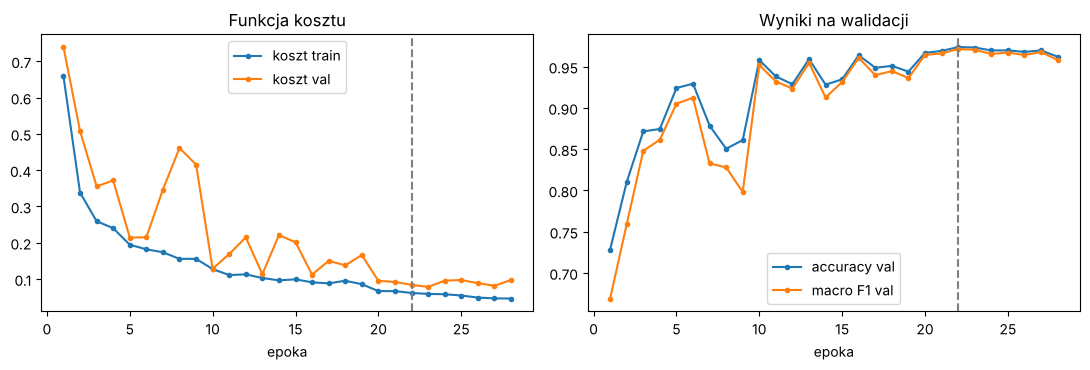

In [12]:
# B4. Krzywe uczenia
historia = pd.DataFrame(historia).set_index("epoka")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
historia[["koszt train", "koszt val"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set_title("Funkcja kosztu")
historia[["accuracy val", "macro F1 val"]].plot(ax=axes[1], marker="o", ms=3)
axes[1].set_title("Wyniki na walidacji")
for ax in axes:
    ax.axvline(najlepsza_epoka, ls="--", c="gray")   # wybrana epoka
plt.tight_layout()
plt.show()

### Wnioski z części B
- **Architektura:** trzy bloki po dwie warstwy konwolucyjne 3 x 3 z normalizacją batcha
  i ReLU, między blokami zmniejszanie obrazu (max pooling) z 28 x 28 do 14 x 14 i 7 x 7.
  Na końcu średnia z każdej mapy cech (global average pooling), dropout 30% i warstwa liniowa
  na 8 klas. Razem 288 936 parametrów. Mała sieć wystarcza na obrazy 28 x 28 i około 12 tys.
  przykładów. Global average pooling zamiast spłaszczania daje mniej parametrów i zostawia mapy
  cech 7 x 7, których używa Grad-CAM.
- **Funkcja kosztu:** entropia krzyżowa (CrossEntropyLoss), standard dla wielu klas.
  **Optymalizator:** AdamW, krok 0,001, lekka kara za duże wagi (0,0001), paczki po 128 obrazów.
  Krok uczenia zmniejsza się o połowę, gdy macro F1 na walidacji przestaje rosnąć.
- **Walidacja:** po każdej epoce liczę macro F1 na zbiorze walidacyjnym i zapamiętuję wagi
  z najlepszej epoki. Gdy przez 6 epok nie ma poprawy, trening się kończy (wczesne zatrzymanie).
  Najlepsza była epoka 22 (macro F1 na walidacji 0,971, accuracy 0,974), trening skończył się po
  28 epokach, u mnie na procesorze trwał około 10 minut.
- **Krzywe uczenia:** w pierwszych kilkunastu epokach wynik na walidacji mocno skacze
  (na przykład w epoce 9 macro F1 spada do 0,80). Po zmniejszeniu kroku uczenia krzywe się
  uspokajają. Koszt na train i na walidacji jest podobny (0,062 i 0,084 w najlepszej epoce),
  więc model nie jest wyraźnie przeuczony.
- **Zbiór testowy** nie był używany w tej części.

## C — Ocena i wyjaśnialność

Oceń wybrany model na oficjalnym zbiorze testowym, używając odpowiednich metryk wieloklasowych i analizy pomyłek. Znajdź w literaturze lub wiarygodnym źródle metodę wizualnego wyjaśniania modeli obrazowych, zastosuj ją do poprawnych i błędnych predykcji z kilku klas oraz omów jej ograniczenia. Podaj źródło.

In [13]:
# C1. Ocena na oficjalnym zbiorze testowym (pierwsze i jedyne użycie testu)
wyjscia_test, _ = przewiduj(model, test_loader)
pred_test = wyjscia_test.argmax(dim=1).numpy()

print(f"accuracy:          {accuracy_score(y_test, pred_test):.4f}")
print(f"balanced accuracy: {balanced_accuracy_score(y_test, pred_test):.4f}")
print(f"macro F1:          {f1_score(y_test, pred_test, average='macro'):.4f}")
print(f"weighted F1:       {f1_score(y_test, pred_test, average='weighted'):.4f}")
print()
print(classification_report(y_test, pred_test, target_names=KLASY, digits=3))

# Kontrola: wynik na testowych obrazach, których identyczna kopia nie występuje w train.
bez_kopii = np.array([h not in h_train for h in hashe(X_test)])
print(f"accuracy bez {np.sum(~bez_kopii)} obrazów skopiowanych z train: "
      f"{accuracy_score(y_test[bez_kopii], pred_test[bez_kopii]):.4f}")

accuracy:          0.9681
balanced accuracy: 0.9647
macro F1:          0.9649
weighted F1:       0.9682

                      precision    recall  f1-score   support

             bazofil      0.954     0.934     0.944       244
           eozynofil      0.995     0.997     0.996       624
         erytroblast      0.997     0.968     0.982       311
niedojrz. granulocyt      0.921     0.929     0.925       579
            limfocyt      0.949     0.988     0.968       243
             monocyt      0.929     0.926     0.928       284
           neutrofil      0.979     0.976     0.977       666
         płytka krwi      0.998     1.000     0.999       470

            accuracy                          0.968      3421
           macro avg      0.965     0.965     0.965      3421
        weighted avg      0.968     0.968     0.968      3421

accuracy bez 5 obrazów skopiowanych z train: 0.9684


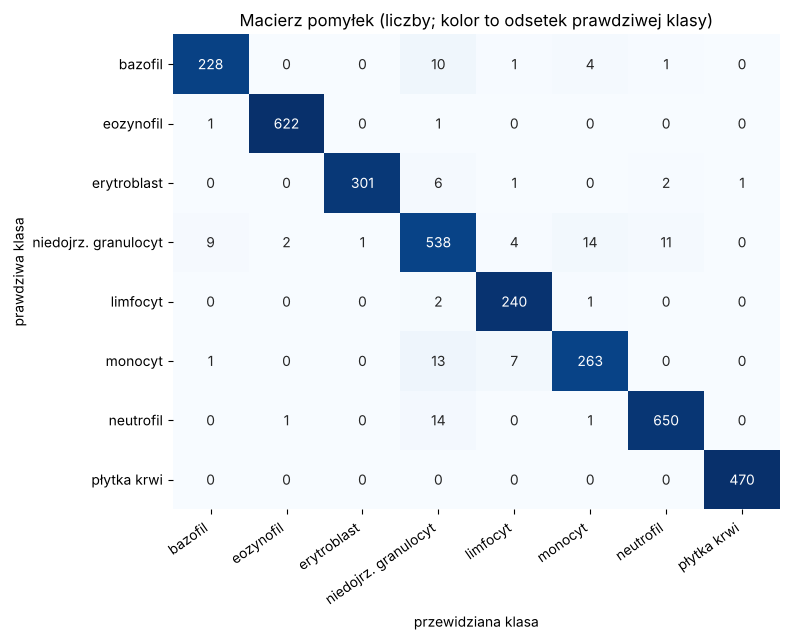

           prawdziwa         przewidziana  liczba
           neutrofil niedojrz. granulocyt      14
niedojrz. granulocyt              monocyt      14
             monocyt niedojrz. granulocyt      13
niedojrz. granulocyt            neutrofil      11
             bazofil niedojrz. granulocyt      10
niedojrz. granulocyt              bazofil       9


In [14]:
# C2. Analiza pomyłek
macierz = confusion_matrix(y_test, pred_test)
macierz_proc = macierz / macierz.sum(axis=1, keepdims=True)    # odsetek w każdym wierszu
plt.figure(figsize=(8, 6.5))
sns.heatmap(macierz_proc, annot=macierz, fmt="d", cmap="Blues", cbar=False,
            xticklabels=KLASY, yticklabels=KLASY)
plt.xlabel("przewidziana klasa")
plt.ylabel("prawdziwa klasa")
plt.title("Macierz pomyłek (liczby; kolor to odsetek prawdziwej klasy)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

pomylki = []
for prawdziwa in range(8):
    for przewidziana in range(8):
        if prawdziwa != przewidziana and macierz[prawdziwa, przewidziana] > 0:
            pomylki.append((KLASY[prawdziwa], KLASY[przewidziana], macierz[prawdziwa, przewidziana]))
pomylki = pd.DataFrame(pomylki, columns=["prawdziwa", "przewidziana", "liczba"])
print(pomylki.sort_values("liczba", ascending=False).head(6).to_string(index=False))

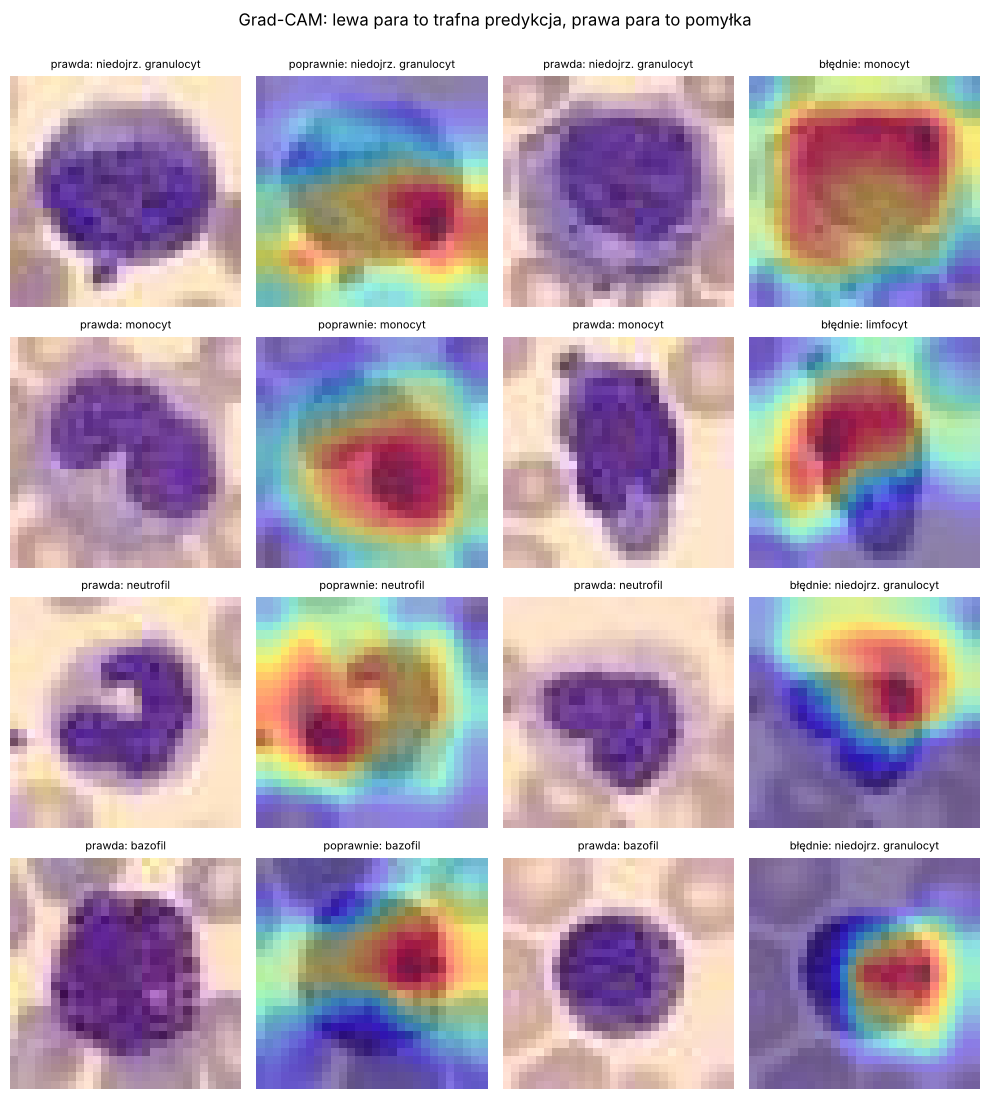

In [15]:
# C3. Grad-CAM: która część obrazu przekonała sieć
# Metoda: Selvaraju i in., "Grad-CAM: Visual Explanations from Deep Networks via
# Gradient-based Localization", ICCV 2017 (https://arxiv.org/abs/1610.02391).
# Pomysł w trzech krokach:
#   1. bierzemy mapy cech z ostatniego bloku konwolucyjnego (128 map 7 x 7),
#   2. liczymy, jak wynik wybranej klasy zmienia się przy zmianie każdej mapy (gradient);
#      średni gradient mapy to jej "waga ważności",
#   3. sumujemy mapy razy wagi i zostawiamy tylko wartości dodatnie (ReLU).
# Wynik powiększamy do 28 x 28 i nakładamy na obraz: jasne miejsca najbardziej zwiększyły wynik klasy.
def grad_cam(model, obraz, klasa):
    model.eval()
    x = transform_eval(obraz).unsqueeze(0).to(DEVICE)    # jeden obraz jako paczka o rozmiarze 1
    mapy = model.cechy(x)                                # (1, 128, 7, 7)
    wynik = model.klasyfikator(mapy)[0, klasa]           # wynik wybranej klasy
    gradienty = torch.autograd.grad(wynik, mapy)[0]      # (1, 128, 7, 7)
    wagi = gradienty.mean(dim=(2, 3), keepdim=True)      # średni gradient każdej mapy
    cam = F.relu((wagi * mapy).sum(dim=1, keepdim=True)) # (1, 1, 7, 7)
    cam = F.interpolate(cam, size=(28, 28), mode="bilinear", align_corners=False)[0, 0]
    cam = cam.detach().cpu().numpy()
    return cam / cam.max() if cam.max() > 0 else cam     # skala 0 do 1


# Wybieram 4 klasy, w których model myli się najczęściej, i dla każdej
# jeden poprawny oraz jeden błędny przykład z testu.
bledy_na_klase = [(macierz[k].sum() - macierz[k, k], k) for k in range(8)]
wybrane_klasy = [k for _, k in sorted(bledy_na_klase, reverse=True)[:4]]

fig, axes = plt.subplots(4, 4, figsize=(10, 11))
for wiersz, klasa in enumerate(wybrane_klasy):
    poprawny = np.where((y_test == klasa) & (pred_test == klasa))[0][0]
    bledny = np.where((y_test == klasa) & (pred_test != klasa))[0][0]
    for kolumna, (i, opis) in enumerate([(poprawny, "poprawnie"), (bledny, "błędnie")]):
        przewidziana = pred_test[i]
        cam = grad_cam(model, X_test[i], przewidziana)   # wyjaśniamy klasę, którą wybrał model
        axes[wiersz, 2 * kolumna].imshow(X_test[i])
        axes[wiersz, 2 * kolumna].set_title(f"prawda: {KLASY[klasa]}", fontsize=8)
        axes[wiersz, 2 * kolumna + 1].imshow(X_test[i])
        axes[wiersz, 2 * kolumna + 1].imshow(cam, cmap="jet", alpha=0.45)
        axes[wiersz, 2 * kolumna + 1].set_title(f"{opis}: {KLASY[przewidziana]}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.suptitle("Grad-CAM: lewa para to trafna predykcja, prawa para to pomyłka", y=1.0)
plt.tight_layout()
plt.show()

### Wnioski z części C
- **Wynik na teście:** accuracy 96,8%, balanced accuracy 96,5%, macro F1 0,965,
  weighted F1 0,968. Wynik na walidacji (97,4%) jest bliski testowi, więc wybór epoki
  nie dopasował się nadmiernie do zbioru walidacyjnego.
- **Klasy:** najłatwiejsze są płytki krwi (F1 0,999) i eozynofile (0,996). Najtrudniejsze są
  niedojrzałe granulocyty (F1 0,925), monocyty (0,928) i bazofile (0,944).
- **Pomyłki:** prawie wszystkie najczęstsze błędy dotyczą niedojrzałych granulocytów:
  neutrofil uznany za niedojrzały granulocyt (14 razy), niedojrzały granulocyt za monocyt (14)
  i odwrotnie (13), za neutrofil (11), bazofil za niedojrzały granulocyt (10) i odwrotnie (9).
  Ma to sens biologiczny: niedojrzałe granulocyty to etapy rozwoju między komórką macierzystą
  a neutrofilem, więc wyglądają pośrednio, a przy 28 x 28 pikselach nie widać ziarnistości,
  które pomagają je odróżnić.
- **Kopie z train:** po pominięciu 5 testowych obrazów, które są też w train, accuracy wynosi
  96,84% zamiast 96,81%, więc duplikaty nie zawyżają wyniku.
- **Grad-CAM, co widać:** przy trafnych predykcjach mapa skupia się na jądrze komórki, którego
  kształt odróżnia typy (na przykład podzielone jądro neutrofila, nerkowate jądro monocytu).
  Przy pomyłkach mapa często obejmuje całą komórkę albo tylko fragment jądra: niedojrzały
  granulocyt uznany za monocyt ma zaznaczoną prawie całą, dużą komórkę, co sugeruje, że model
  oparł się na jej wielkości i ogólnym kształcie.
- **Ograniczenia Grad-CAM:**
  1. mapa ma tylko 7 x 7 pól i jest rozciągana do 28 x 28, więc pokazuje rozmyte plamy,
     a nie pojedyncze struktury, takie jak ziarnistości,
  2. pokazuje, **gdzie** model patrzy, ale nie **co** tam zobaczył (kolor, kształt czy fakturę),
  3. wynik zależy od wybranej warstwy i od tego, którą klasę wyjaśniamy,
  4. nie ma gwarancji, że mapa wiernie oddaje rozumowanie modelu. Adebayo i in. (2018)
     pokazali, że część metod daje podobne mapy nawet dla sieci z losowymi wagami. Grad-CAM
     przeszedł ich testy lepiej niż wiele innych metod, ale pozostaje narzędziem jakościowym,
  5. obejrzałem tylko 8 przykładów, więc to ilustracja, a nie dowód statystyczny.
- **Co można poprawić:** użyć wersji zbioru w wyższej rozdzielczości (MedMNIST ma też obrazy
  64 x 64 i większe), wypróbować wagi klas w funkcji kosztu albo sieć wstępnie wytrenowaną.
- **Odtwarzalność:** ustalone ziarno losowości (42) dla Pythona, NumPy, PyTorcha i tasowania
  danych. Na karcie graficznej wyniki mogą się minimalnie różnić od uzyskanych na procesorze.

## Oddanie zadania

Zapisz kod, wyniki, wykresy i uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i zadbaj o odtwarzalność rozwiązania. Umieść rozwiązania w swoim repozytorium.

**Źródła:**
- J. Yang i in., "MedMNIST v2: A large-scale lightweight benchmark for 2D and 3D biomedical
  image classification", Scientific Data, 2023 (https://arxiv.org/abs/2110.14795), opis zbioru.
- A. Acevedo i in., "A dataset of microscopic peripheral blood cell images for development of
  automatic recognition systems", Data in Brief, 2020, źródłowe zdjęcia BloodMNIST.
- R. R. Selvaraju i in., "Grad-CAM: Visual Explanations from Deep Networks via Gradient-based
  Localization", ICCV 2017 (https://arxiv.org/abs/1610.02391), metoda wyjaśniania.
- J. Adebayo i in., "Sanity Checks for Saliency Maps", NeurIPS 2018
  (https://papers.nips.cc/paper/8160-sanity-checks-for-saliency-maps), ograniczenia map istotności.
- dokumentacja PyTorch i torchvision.

**Narzędzia AI:** Claude (Anthropic), pomoc przy pisaniu kodu i wyjaśnianiu bibliotek.